# New Section

# Exploratory and Statistical Analysis of Student Performance

## 1. Project Overview

This project explores the relationships between student characteristics and academic performance using Python-based exploratory data analysis (EDA).

The analysis focuses on study time, student absences, previous academic performance, and the distribution of final grades.

The objective is to identify meaningful statistical patterns, visualize relationships, and evaluate the limitations of the observed findings.

### Research Questions

1. How does weekly study time relate to students' final grades?
2. Is there a linear relationship between student absences and academic performance?
3. How strongly are previous grades (G1 and G2) associated with final grades (G3)?
4. How are final grades distributed, and how do zero grades influence summary statistics?

### Tools and Technologies

- **Python:** Data analysis and statistical calculations
- **Pandas:** Data manipulation and descriptive statistics
- **Matplotlib:** Data visualization
- **Google Colab:** Notebook development environment

### Dataset

**Source:** UCI Machine Learning Repository — Student Performance Dataset

The analysis uses the Mathematics dataset, containing 395 student records and 33 variables.

**Target variable:** G3 (Final Grade, 0–20)

**Dataset URL:** https://archive.ics.uci.edu/dataset/320/student+performance

In [24]:
import pandas as pd

df = pd.read_csv("data/student-mat.csv", sep=";")

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [25]:

# Check missing values
print("Total missing values:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Check grade ranges
print("\nFinal grade range:")
print(df["G3"].min(), "-", df["G3"].max())

# Check study time categories
print("\nStudy time categories:")
print(df["studytime"].value_counts().sort_index())


Total missing values:
0

Duplicate rows:
0

Final grade range:
0 - 20

Study time categories:
studytime
1    105
2    198
3     65
4     27
Name: count, dtype: int64


### Data Quality Assessment

The dataset contains 395 student records and 33 variables.

Initial data quality checks identified no missing values or completely duplicated rows. Final grades (G3) ranged from 0 to 20, while study time categories were within the expected range of 1 to 4.

Based on these initial checks, no missing-value imputation or duplicate removal was required.

Further validation of other variables may still be necessary.

In [26]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

# Display basic descriptive statistics
df.describe()


Dataset shape: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [27]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

# Display basic descriptive statistics
df.describe()


Dataset shape: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [28]:

# Analyze final grades (G3)

print("Average final grade:", round(df["G3"].mean(), 2))
print("Median final grade:", df["G3"].median())
print("Highest final grade:", df["G3"].max())
print("Lowest final grade:", df["G3"].min())
print("Standard deviation:", round(df["G3"].std(), 2))


Average final grade: 10.42
Median final grade: 11.0
Highest final grade: 20
Lowest final grade: 0
Standard deviation: 4.58


In [29]:

# Average final grade for each study time category

study_analysis = df.groupby("studytime")["G3"].agg(
    ["count", "mean", "median"]
)

print(study_analysis)


           count       mean  median
studytime                          
1            105  10.047619    10.0
2            198  10.171717    11.0
3             65  11.400000    12.0
4             27  11.259259    12.0


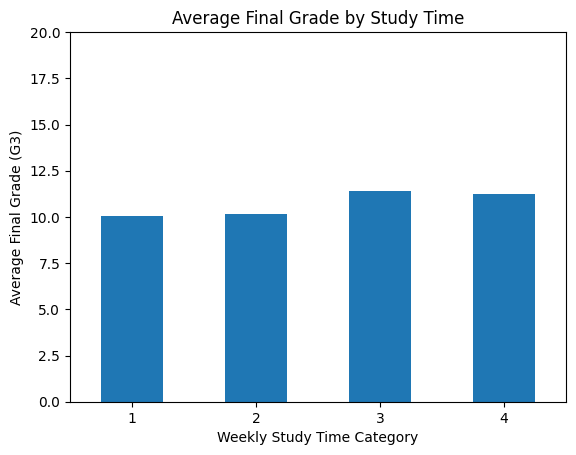

In [30]:

import matplotlib.pyplot as plt

# Plot average grades by study time category
study_analysis["mean"].plot(kind="bar")

plt.title("Average Final Grade by Study Time")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Average Final Grade (G3)")
plt.xticks(rotation=0)
plt.ylim(0, 20)

plt.show()


### Finding 1: Study Time and Academic Performance

Students reporting higher weekly study time generally achieved slightly higher average final grades. The highest average grade (11.40/20) was observed in study time category 3, while category 4 had a slightly lower average (11.26/20).

However, the differences were relatively small, and the number of students varied across categories. Therefore, these results do not establish a causal relationship between study time and academic performance.

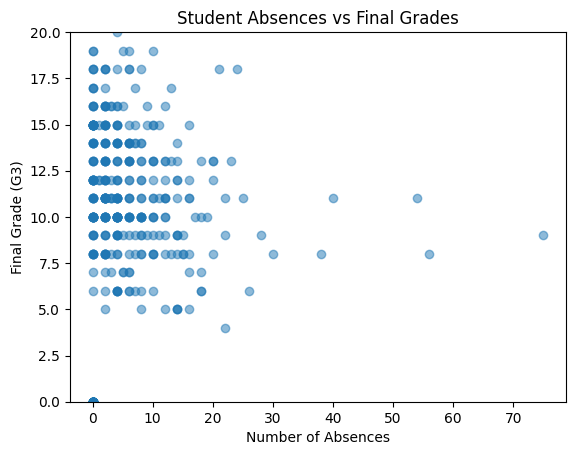

Correlation: 0.034


In [31]:

import matplotlib.pyplot as plt

# Create a scatter plot
plt.scatter(df["absences"], df["G3"], alpha=0.5)

plt.title("Student Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.ylim(0, 20)

plt.show()

# Calculate Pearson correlation
correlation = df["absences"].corr(df["G3"])

print("Correlation:", round(correlation, 3))


In [32]:

# Examine the distribution of absences
print(df["absences"].describe())

# Recalculate correlation for students
# with 20 or fewer absences
filtered_df = df[df["absences"] <= 20]

correlation_filtered = filtered_df["absences"].corr(
    filtered_df["G3"]
)

print("Original correlation:",
      round(df["absences"].corr(df["G3"]), 3))

print("Filtered correlation:",
      round(correlation_filtered, 3))

print("Students included:", len(filtered_df))


count    395.000000
mean       5.708861
std        8.003096
min        0.000000
25%        0.000000
50%        4.000000
75%        8.000000
max       75.000000
Name: absences, dtype: float64
Original correlation: 0.034
Filtered correlation: 0.084
Students included: 380


### Finding 2: Absences and Academic Performance

The Pearson correlation between student absences and final grades was approximately 0.034, indicating almost no linear relationship in the full dataset.

To examine the sensitivity of this result to unusually high absence values, a second analysis was performed using students with 20 or fewer absences (380 out of 395 students).

The correlation increased slightly to 0.084 but remained very weak.

These findings suggest that absences alone do not show a meaningful linear association with final grades in this dataset. However, nonlinear relationships and the effects of other variables have not yet been investigated.

In [33]:

# Select the three grade columns
grades = df[["G1", "G2", "G3"]]

# Calculate the correlation matrix
correlation_matrix = grades.corr()

print(correlation_matrix)


          G1        G2        G3
G1  1.000000  0.852118  0.801468
G2  0.852118  1.000000  0.904868
G3  0.801468  0.904868  1.000000


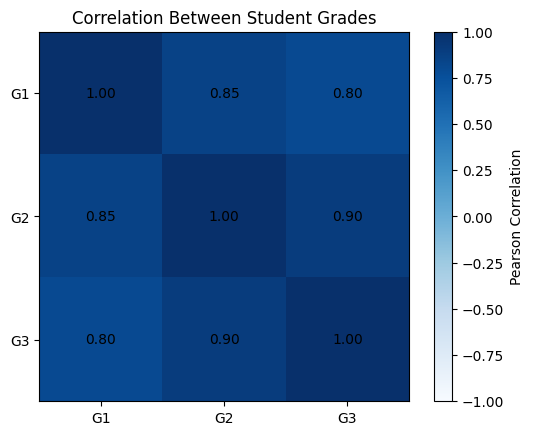

In [34]:
import matplotlib.pyplot as plt

plt.imshow(correlation_matrix, cmap="Blues", vmin=-1, vmax=1)

plt.colorbar(label="Pearson Correlation")

plt.xticks(range(3), ["G1", "G2", "G3"])
plt.yticks(range(3), ["G1", "G2", "G3"])

for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Between Student Grades")
plt.show()

### Finding 3: Previous Grades and Final Academic Performance

The correlation analysis revealed strong positive relationships among students' grades.

The strongest correlation was observed between second-period grades (G2) and final grades (G3), with a Pearson correlation coefficient of 0.905. First-period grades (G1) were also strongly correlated with final grades (r = 0.801).

These findings suggest that students' earlier academic performance is strongly associated with their final outcomes. However, correlation does not establish causation.

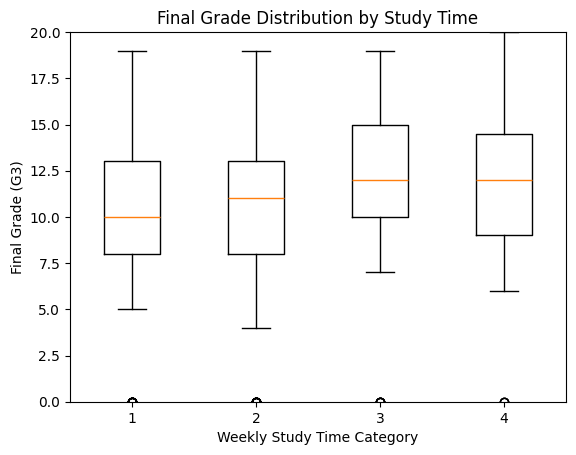

In [35]:

import matplotlib.pyplot as plt

# Final grades grouped by study time
groups = [
    df[df["studytime"] == category]["G3"]
    for category in [1, 2, 3, 4]
]

plt.boxplot(groups, tick_labels=["1", "2", "3", "4"])

plt.title("Final Grade Distribution by Study Time")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Final Grade (G3)")
plt.ylim(0, 20)

plt.show()


### Additional Analysis: Grade Distribution by Study Time

The box plot shows that students in study time categories 3 and 4 had slightly higher median final grades (12/20) compared with categories 1 and 2 (10/20 and 11/20, respectively).

However, the grade distributions overlap considerably, suggesting that study time alone does not clearly distinguish students with higher and lower academic performance.

Several zero-grade observations appear as potential outliers under the box plot's statistical rule. These values were retained because they fall within the valid grading range.

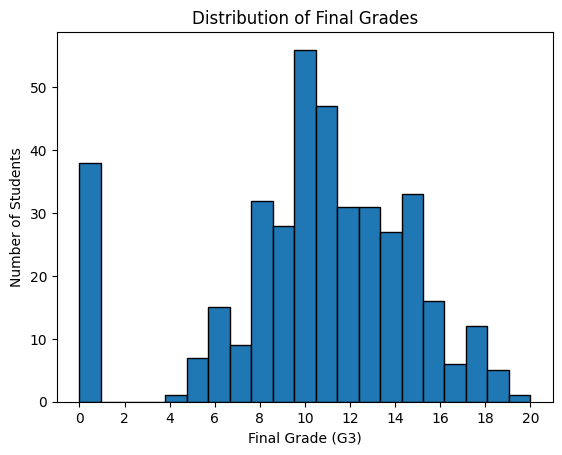

In [36]:
import matplotlib.pyplot as plt

plt.hist(df["G3"], bins=21, edgecolor="black")

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.xticks(range(0, 21, 2))

plt.show()

In [37]:

# Count students who received a final grade of zero
zero_grades = (df["G3"] == 0).sum()

# Calculate their percentage
zero_percentage = zero_grades / len(df) * 100

# Find the most common final grade
most_common_grade = df["G3"].mode()[0]

print("Students with grade 0:", zero_grades)
print("Percentage:", round(zero_percentage, 2), "%")
print("Most common final grade:", most_common_grade)


Students with grade 0: 38
Percentage: 9.62 %
Most common final grade: 10


### Finding 4: Distribution of Final Grades

The distribution of final grades was concentrated mainly between 8 and 15, with a mean of 10.42 and a median of 11 out of 20.

The most frequent final grade was 10. Notably, 38 out of 395 students (9.62%) received a final grade of zero.

This concentration of zero grades highlights an unusual feature of the distribution. However, the dataset does not establish why these students received zero grades, so no assumptions were made about the cause.

In [38]:
# Calculate mean and median using all grades
overall_mean = df["G3"].mean()
overall_median = df["G3"].median()

# Analyze grades above zero without modifying the original dataset
nonzero_grades = df.loc[df["G3"] > 0, "G3"]

print("Overall mean:", round(overall_mean, 2))
print("Mean excluding zero grades:", round(nonzero_grades.mean(), 2))

print("Overall median:", overall_median)
print("Median excluding zero grades:", nonzero_grades.median())

Overall mean: 10.42
Mean excluding zero grades: 11.52
Overall median: 11.0
Median excluding zero grades: 11.0


### Additional Analysis: Impact of Zero Grades

To examine how zero grades affect the overall distribution, descriptive statistics were recalculated after temporarily excluding students with a final grade of zero.

The mean increased from 10.42 to 11.52, while the median remained unchanged at 11.

This indicates that zero grades have a noticeable impact on the overall mean, whereas the median was more stable in this comparison.

Zero grades were retained in the original dataset, as they are within the valid grading range. The exclusion was performed only as a sensitivity analysis.

## Conclusion

This project investigated the relationships between student characteristics and academic performance using exploratory data analysis, descriptive statistics, correlation analysis, and data visualization.

**Key Findings**

- **Previous academic performance:** Previous grades showed the strongest linear associations with final grades. In particular, second-period grades (G2) had a strong positive correlation with final grades (G3), with a Pearson correlation coefficient of 0.905.

- **Study time:** Students in higher study-time categories generally had slightly higher average final grades. However, the differences were relatively small, and the grade distributions overlapped considerably.

- **Absences:** The correlation between absences and final grades was very weak (r = 0.034). After excluding observations with more than 20 absences for a sensitivity analysis, the correlation remained weak (r = 0.084).

- **Grade distribution:** Most final grades were concentrated around the middle of the grading scale. A total of 38 students (9.62%) received a final grade of zero. Excluding these observations increased the mean from 10.42 to 11.52, while the median remained unchanged at 11.

**Limitations**

The dataset is observational, so the findings cannot establish causal relationships. The analysis focused primarily on descriptive statistics and linear correlations; potential nonlinear relationships and confounding variables were not fully investigated. Additionally, the dataset represents a specific student population and may not generalize to other educational contexts.

**Final Conclusion**

Previous academic performance showed the strongest association with final grades among the variables examined. The analysis also demonstrated the importance of examining data distributions, group differences, and sensitivity to unusual observations rather than relying solely on averages.